# 02 · Features

**Qué predice el modelo y en qué momento:** cada mañana del día *d+1*, con el cierre de cartera del día *d*, el modelo estima la probabilidad de que cada crédito en mora **pague al menos una cuota entre los días d+1 y d+7** (`paga_7d`).

Toda feature debe existir en ese momento: solo puede usar el cierre del día *d* y eventos registrados hasta el día *d*.

## 1. Carga y construcción de la base del modelo

El orden importa:
1. **Features** con la OBT completa, porque usan ventanas de días anteriores y siguientes.
2. **Target**, que excluye los últimos 7 días (no tienen su semana siguiente completa).
3. **Población**: solo créditos en mora (hallazgo del EDA).

`cargar_base()` de `src/pipeline.py` hace los tres pasos en ese orden, y se importa aquí.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.pipeline import cargar_base

base = cargar_base()

# Feature evaluada y descartada (sección 3): solo se calcula aquí, para mostrar la evidencia
dias_a_cuota = (pd.to_datetime(base["fecha_proxima_cuota"]) - base["fecha_corte"]).dt.days
base["cuota_por_vencer_7d"] = dias_a_cuota.between(1, 7).astype(int)

print("Filas de la base del modelo:", base.shape[0])
print("% que paga en 7 días:", round(base["paga_7d"].mean() * 100, 2))

Filas de la base del modelo: 71978
% que paga en 7 días: 18.67


**Verificación:** la base del modelo tiene 71,978 filas y 18.67% de positivos, los mismos valores del EDA (sección 6). Las funciones importadas de `src/datos.py` y `src/pipeline.py` reproducen la misma población y el mismo target; construir las features antes del target no cambió ninguna fila.

## 2. Evidencia de que cada feature aporta

Para cada feature binaria se compara el % que paga en 7 días cuando la feature vale 1 frente a cuando vale 0. Si los dos porcentajes son muy distintos, la feature separa a los que pagan de los que no, y aporta información al modelo. La línea punteada es el promedio de la población (18.67%).

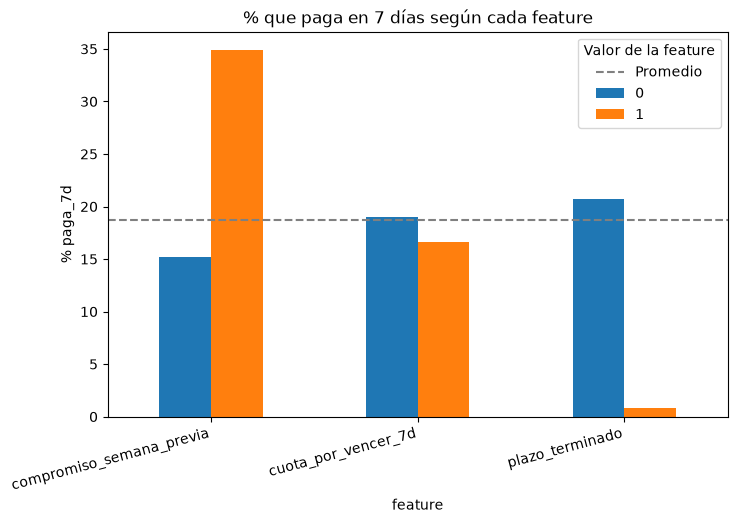

,feature,valor,filas,% paga_7d
0,plazo_terminado,0,64655,20.7
1,plazo_terminado,1,7323,0.8
2,compromiso_semana_previa,0,59135,15.2
3,compromiso_semana_previa,1,12843,34.9
4,cuota_por_vencer_7d,0,62197,19.0
5,cuota_por_vencer_7d,1,9781,16.6


In [2]:
features = ["plazo_terminado", "compromiso_semana_previa", "cuota_por_vencer_7d"]

filas = []
for f in features:
    for valor in [0, 1]:
        grupo = base[base[f] == valor]
        filas.append({"feature": f, "valor": valor, "filas": len(grupo),
                      "% paga_7d": round(grupo["paga_7d"].mean() * 100, 1)})
evidencia = pd.DataFrame(filas)

tabla_grafico = evidencia.pivot(index="feature", columns="valor", values="% paga_7d")
tabla_grafico.plot(kind="bar", figsize=(8, 5))
plt.axhline(base["paga_7d"].mean() * 100, color="gray", linestyle="--", label="Promedio")
plt.title("% que paga en 7 días según cada feature")
plt.ylabel("% paga_7d")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Valor de la feature")
plt.savefig("../docs/figuras/features_evidencia.png", bbox_inches="tight")
plt.show()

evidencia

**Hallazgo: `plazo_terminado` y `compromiso_semana_previa` separan claramente a los que pagan.**
- **`plazo_terminado`** (sale del hallazgo del EDA sobre faltantes estructurales):
  - **Evidencia:** paga el 0.8% cuando vale 1 (7,323 filas), frente al 20.7% cuando vale 0.
  - **Existe al predecir:** se calcula con `cuotas_por_pagar` y `cuotas_mora` del cierre del día *d*.
  - **Codificación:** ya es binaria (0/1); no necesita codificación.
- **`compromiso_semana_previa`** (sale de las bases de seguimiento de compromisos del área de cobranzas):
  - **Evidencia:** paga el 34.9% cuando vale 1 (12,843 filas), frente al 15.2% cuando vale 0: 2.3 veces más.
  - **Existe al predecir:** usa las gestiones de los días *d−6* a *d*, que se registran el día de la llamada y se ven en la mañana de *d+1*.
  - **Codificación:** binaria (0/1); no necesita codificación.
- **`cuota_por_vencer_7d`:** la diferencia es pequeña (16.6% vs. 19.0%) y puede estar mezclada con el tramo de mora. Se revisa dentro de cada tramo antes de decidir si se usa.

## 3. ¿`cuota_por_vencer_7d` aporta algo dentro de cada tramo de mora?

Se compara el % que paga con y sin cuota por vencer **dentro de cada tramo**. Si la diferencia desaparece, el efecto observado se debía al tramo de mora, y la feature no aporta información propia.

In [3]:
orden = ["1-30", "31-60", "61-90", "91-120", "+120"]
pd.crosstab(base["rango_mora"], base["cuota_por_vencer_7d"],
            values=base["paga_7d"], aggfunc="mean").reindex(orden).mul(100).round(1)

cuota_por_vencer_7d,0,1
rango_mora,,
1-30,33.8,33.7
31-60,25.7,25.7
61-90,16.3,11.7
91-120,7.2,9.8
+120,0.9,1.1


**Hallazgo: `cuota_por_vencer_7d` no aporta información propia y se descarta.**
- **Evidencia:** dentro de cada tramo de mora, el % que paga es prácticamente igual con y sin cuota por vencer (1-30: 33.8% vs. 33.7%; 31-60: 25.7% vs. 25.7%). En los demás tramos las diferencias son pequeñas y en direcciones opuestas. La diferencia global (19.0% vs. 16.6%) se explicaba por el tramo de mora.
- **Consecuencia en el modelo:** no se incluye. Agregar una feature sin información propia solo suma ruido.

## 4. ¿Las features seleccionadas aportan dentro de cada tramo de mora?

Misma prueba para `plazo_terminado` y `compromiso_semana_previa`: si la diferencia se mantiene dentro de los tramos, la feature aporta información que `dias_mora` no tiene.

In [4]:
for f in ["plazo_terminado", "compromiso_semana_previa"]:
    print(f)
    display(pd.crosstab(base["rango_mora"], base[f], values=base["paga_7d"],
                        aggfunc="mean").reindex(orden).mul(100).round(1))

plazo_terminado


plazo_terminado,0,1
rango_mora,,
1-30,34.1,0.0
31-60,25.9,16.0
61-90,16.2,0.0
91-120,7.0,19.8
+120,1.1,0.3


compromiso_semana_previa


compromiso_semana_previa,0,1
rango_mora,,
1-30,32.6,37.1
31-60,18.6,37.5
61-90,11.8,29.9
91-120,6.8,12.8
+120,0.7,10.4


**Verificación:** ¿cuántas filas con plazo terminado hay en cada tramo de mora?

In [5]:
pd.crosstab(base["rango_mora"], base["plazo_terminado"]).reindex(orden)

plazo_terminado,0,1
rango_mora,,
1-30,31087,286
31-60,7452,131
61-90,2883,91
91-120,1837,96
+120,21396,6719


**Hallazgo: `compromiso_semana_previa` aporta en todos los tramos; `plazo_terminado` aporta menos, pero también.**
- **`compromiso_semana_previa`:** en todos los tramos, quien tuvo un compromiso en la última semana paga más (31-60: 37.5% vs. 18.6%; 61-90: 29.9% vs. 11.8%; +120: 10.4% vs. 0.7%). Aporta información que `dias_mora` no tiene.
- **`plazo_terminado`:** el 92% de sus casos está en el tramo +120 (6,719 de 7,323), así que buena parte de su efecto coincide con el tramo. Aun así, dentro de +120, el grupo más grande, paga el 0.3% con plazo terminado frente al 1.1% sin él (casi 4 veces menos). En los demás tramos hay menos de 300 filas, que corresponden a pocos créditos, y sus porcentajes no son confiables.
- **Consecuencia en el modelo:** se usan las dos features. `compromiso_semana_previa` es la de mayor aporte; `plazo_terminado` ayuda a distinguir, dentro de la mora más alta, a los créditos que prácticamente no pagan.

## 5. Resumen de features

| Feature | Origen | Evidencia | ¿Existe al predecir (mañana de *d+1*)? | Codificación |
|---|---|---|---|---|
| `compromiso_semana_previa` | Bases de seguimiento de compromisos del área de cobranzas; correlación de la gestión con el pago (EDA, sección 10) | 34.9% vs. 15.2% de pago; la diferencia se mantiene en todos los tramos | Sí: gestiones de los días *d−6* a *d*, registradas el día de la llamada | Binaria (0/1) |
| `plazo_terminado` | Hallazgo del EDA sobre faltantes estructurales de `fecha_proxima_cuota` | 0.8% vs. 20.7% de pago; dentro de +120, 0.3% vs. 1.1% | Sí: cuotas del cierre del día *d* | Binaria (0/1) |
| ~~`cuota_por_vencer_7d`~~ | Bases del área de cobranzas (cuota por vencer) | Sin diferencia dentro de los tramos | — | **Descartada** |

**Variable de tratamiento para el efecto incremental:** `gestionado_7d` = 1 si el crédito se gestiona entre los días *d+1* y *d+7*. No es una feature que el modelo "adivine": representa **la decisión de llamar**. En el S-learner, el modelo se entrena con ella, y al priorizar se predice cada crédito dos veces (gestionado y no gestionado). La diferencia es el efecto incremental.

**Variables que no entran al modelo:** identificadores; `anio` y `mes` (constantes); `fecha_primera_cuota_mora` (redundante con `dias_mora`); `es_cancelada` y `tiene_cartera` (estado actual, fuga temporal); `num_pagos_dia` y `monto_pagado_dia` (fuga del objetivo).